In [1]:
from anemone.inversion import Resistivity
import torch

[<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>]

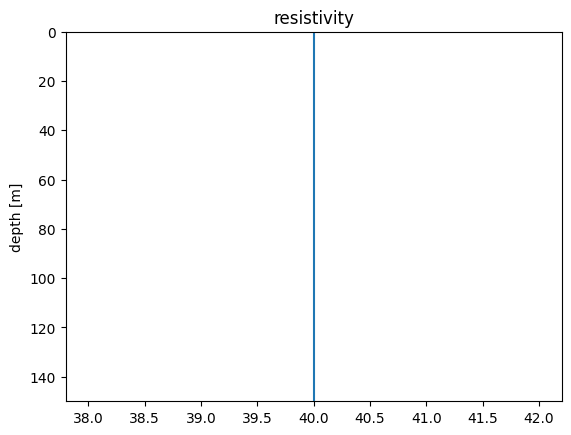

In [2]:
res = Resistivity.smooth(torch.ones(31)*40, torch.logspace(-0.1, 2, 30))
res.plot()

In [4]:
import sys
sys.path.append('../')

In [5]:
from panels import *

In [ ]:
from dataclasses import dataclass

@dataclass
class StartingModelSettings(PanelSettings):
    line_color: str='#ff0000'


class StartingModel(ModelGraph):
    starting_rho: float = 40.0
    def __init__(self, data, **kwargs):
        settings = StartingModelSettings(id='starting_model', **kwargs)
        super().__init__(id='starting_model', settings=settings)
        self.data = data

    def render(self):
        # fig = make_subplots(rows=1, cols=2, shared_yaxes=True)
        # Add the step plot for resistivity
        fig = px.line(self.data,
            x='resistivity',
            y='depth',
            markers=True,
            color_discrete_sequence=[self.settings.line_color, self.settings.line_color],
            hover_data={'resistivity': ':.2f Ω⋅m', 'depth': False},  # Add tooltip for resistivity values
            # hover='resistivity'  # Add tooltip for resistivity values
        )
        
        for i in [0.5, 1, 2]:
            z = self.data['depth']
            y = 10+90*(1 / (1 + np.exp(-20.*(z-150)/z.max())))**i
            fig.add_scatter(x=y, y=z, line=dict(color='grey'))#, row=1, col=2)

        # Update layout to match typical resistivity plot conventions
        fig.update_layout(
            title='Inversion Starting Model',
            xaxis_title='resistivity [Ω⋅m]',
            yaxis_title='depth [m]',
            xaxis_type='log',  # Resistivity is typically plotted on log scale
            yaxis_type='linear',
            yaxis=dict(autorange='reversed'),  # Depth increases downward
            xaxis=dict(range=[-0.1,3.1]),  # Set x-axis range for resistivity
            showlegend=True,
            modebar=dict(remove=['toImage', 'zoom', 'zoomIn', 'zoomOut', 'pan', 'select']),
        )
        fig.add_shape(type='line', x0=self.starting_rho, x1=self.starting_rho,
                      y0=self.data['depth'].min(), y1=self.data['depth'].max(), 
                      xref='x1', yref='y1',
                      line=dict(color=self.settings.line_color, dash='dash'),
                      editable=True)

        return fig
    
    def initialize(self):
        return html.Div([dcc.Graph(figure=self.render(), id=self.id, mathjax=True, 
                                   style={'align': 'center', 'pad': '10px'}, 
                                   config=dict(edits={'shapePosition':True}, displayModeBar=False)),
                        ],
                        )
    
    def add_callbacks(self, app):
        super().add_callbacks(app)

        @app.callback(
            Output(self.id, 'figure', allow_duplicate=True),
            Input(self.id, 'relayoutData'),
            prevent_initial_call=True
        )
        def update_starting_model(relayoutData):
            self.starting_rho = int(relayoutData.get('shapes[0].x0', self.starting_rho))
            self.data['resistivity'] = self.starting_rho
            return self.render()

In [186]:
import pandas as pd

df = pd.DataFrame({
    'resistivity': [40.0] * 31,  # Default resistivity values
    'depth': np.logspace(0, log10(300), 31)  # Example depth values from 0 to 300 meters
})

x1 = StartingModel(df)
#x1.initialize()

In [187]:
import dash
from dash import Dash

app = Dash(__name__, suppress_callback_exceptions=True, assets_folder='assets')
app.title = "sea anemone"
app.layout = x1.initialize()
x1.add_callbacks(app)
app.run(debug=True, use_reloader=False)  # Set use_reloader=False to avoid double callbacks during development

In [3]:
def hex_to_rgb(hex_color):
    # Remove the '#' if present
    hex_color = hex_color.lstrip('#')
    # Convert hex to RGB
    return tuple(int(hex_color[i:i+2], 16) for i in (0, 2, 4))

# Example usage
hex_color = "#34A2FE"
rgb_color = hex_to_rgb(hex_color)
print(f"HEX: {hex_color} -> RGB: {rgb_color}")

import plotly.graph_objs as go
import random

f = go.FigureWidget()
f.layout.hovermode = 'closest'
f.layout.hoverdistance = -1 #ensures no "gaps" for selecting sparse data
default_linewidth = 2
highlighted_linewidth_delta = 2

# just some traces with random data points  
num_of_traces = 5
random.seed = 42
for i in range(num_of_traces):
    y = [random.random() + i / 2 for _ in range(100)]
    trace = go.Scatter(y=y, mode='lines', line={ 'width': default_linewidth, 'color':'rgba(125,125,125,0.5)'})
    f.add_trace(trace)

# our custom event handler
def update_trace(trace, points, selector):
    # this list stores the points which were clicked on
    # in all but one trace they are empty
    if len(points.point_inds) == 0:
        return
        
    for i,_ in enumerate(f.data):
        
        if i == points.trace_index:
            f.data[i]['line']['width'] = default_linewidth + highlighted_linewidth_delta
            f.data[i]['line']['color'] = 'rgba(0,0,255,1)'
        else:
            f.data[i]['line']['width'] = default_linewidth
            f.data[i]['line']['color'] = 'rgba(125,125,125,0.5)'

# we need to add the on_click event to each trace separately       
for i in range( len(f.data) ):
    f.data[i].on_click(update_trace)
f.show()

HEX: #34A2FE -> RGB: (52, 162, 254)


FigureWidget({
    'data': [{'line': {'color': 'rgba(125,125,125,0.5)', 'width': 2},
              'mode': 'lines',
              'type': 'scatter',
              'uid': '28bcc32c-a08f-4967-9249-f1d80d5e7c03',
              'y': [0.6610737886612997, 0.9186636372489504, 0.06421141368846561,
                    0.20997704247587845, 0.8617192924082467, 0.22319364320927648,
                    0.0547561973206645, 0.6061994361207809, 0.5011070474053583,
                    0.4690041973178055, 0.39914319750751726, 0.7807782927497375,
                    0.6956889417339154, 0.7407171644417423, 0.6794597171544798,
                    0.3672854779158061, 0.43474642135259667, 0.022638189631948524,
                    0.8829098832289487, 0.5938737471722354, 0.25294959938767414,
                    0.9215131239159937, 0.7473162389605027, 0.7734402798379848,
                    0.8513196942506069, 0.21083755996286213, 0.10303495618354053,
                    0.5322467892127429, 0.10925803304469195,

In [ ]:
import dash
from dash import html
from dash import dcc

app = dash.Dash(__name__)
# app.css.append_css({'external_url': 'https://codepen.io/chriddyp/pen/dZVMbK.css'})

styles = {'pre': {'border': 'thin lightgrey solid', 'overflowX': 'scroll'}}

app.layout = html.Div(className='row', children=[
    dcc.Graph(figure=f),
])

app.run(debug=True, use_reloader=False)  # Set use_reloader=False to avoid double callbacks during development

In [31]:
import dash
from dash import html, dcc, Input, Output, State, callback_context
import plotly.graph_objects as go
import random
import numpy as np

# Create the figure with multiple traces
def create_figure(highlighted_trace=None):
    fig = go.Figure()
    fig.layout.hovermode = 'closest'
    fig.layout.hoverdistance = -1  # ensures no "gaps" for selecting sparse data
    
    default_linewidth = 2
    highlighted_linewidth_delta = 2
    
    # Create traces with random data points  
    num_of_traces = 5
    # random.seed(42)
    
    for i in range(num_of_traces):
        y = [random.random() + i / 2 for _ in range(100)]
        
        # Determine if this trace should be highlighted
        is_highlighted = (highlighted_trace is not None and i == highlighted_trace)
        
        line_width = default_linewidth + highlighted_linewidth_delta if is_highlighted else default_linewidth
        line_color = 'rgba(0,0,255,1)' if is_highlighted else 'rgba(125,125,125,0.5)'
        
        trace = go.Scatter(
            y=y, 
            mode='lines', 
            line={'width': line_width, 'color': line_color},
            name=f'Trace {i}',
            customdata=[i] * len(y),  # Store trace index for identification
            hovertemplate=f'<b>Trace {i}</b><br>Index: %{{x}}<br>Value: %{{y:.3f}}<extra></extra>'
        )
        fig.add_trace(trace)
    
    fig.update_layout(
        title='Interactive Multi-Trace Plot<br><sub>Click on a trace to highlight it</sub>',
        showlegend=True,
        height=600
    )
    
    return fig

# Initialize the app
app = dash.Dash(__name__)

# Global variable to store the currently highlighted trace
highlighted_trace = None

app.layout = html.Div([
    html.H1("Interactive Trace Highlighting", style={'textAlign': 'center'}),
    
    dcc.Graph(
        id='interactive-traces',
        figure=create_figure(),
        style={'height': '600px'}
    ),
    
    html.Div(id='trace-info', 
             style={
                 'margin': '20px', 
                 'padding': '15px', 
                 'border': '2px solid #ddd',
                 'borderRadius': '5px',
                 'backgroundColor': '#f9f9f9'
             }),
    
    # Store for maintaining highlighted trace state
    dcc.Store(id='highlighted-trace-store', data=None)
])

@app.callback(
    [Output('interactive-traces', 'figure'),
     Output('trace-info', 'children'),
     Output('highlighted-trace-store', 'data')],
    [Input('interactive-traces', 'clickData'),
     Input('interactive-traces', 'hoverData')],
    [State('highlighted-trace-store', 'data')]
)
def update_trace_highlighting(clickData, hoverData, current_highlighted):
    ctx = callback_context
    
    # Determine what triggered the callback
    if not ctx.triggered:
        # Initial load
        fig = create_figure()
        info = html.P("Click on a trace to highlight it permanently.")
        return fig, info, None
    
    trigger_id = ctx.triggered[0]['prop_id'].split('.')[0]
    
    # Handle clicks - these change the permanently highlighted trace
    if trigger_id == 'interactive-traces' and 'clickData' in ctx.triggered[0]['prop_id']:
        if clickData and 'points' in clickData:
            clicked_trace = clickData['points'][0]['customdata'][0]
            
            # Toggle: if clicking on already highlighted trace, unhighlight it
            new_highlighted = None if current_highlighted == clicked_trace else clicked_trace
            
            fig = create_figure(highlighted_trace=new_highlighted)
            
            if new_highlighted is not None:
                info = html.Div([
                    html.H4(f"Selected Trace: {new_highlighted}", style={'color': 'blue'}),
                    html.P(f"Click on Trace {new_highlighted} again to deselect, or click another trace to switch selection.")
                ])
            else:
                info = html.P("No trace selected. Click on a trace to highlight it.")
            
            return fig, info, new_highlighted
    
    # If no click occurred, maintain current state
    fig = create_figure(highlighted_trace=current_highlighted)
    
    if current_highlighted is not None:
        info = html.Div([
            html.H4(f"Selected Trace: {current_highlighted}", style={'color': 'blue'}),
            html.P(f"Click on Trace {current_highlighted} again to deselect, or click another trace to switch selection.")
        ])
    else:
        info = html.P("Click on a trace to highlight it permanently.")
    
    return fig, info, current_highlighted

# if __name__ == '__main__':
#     app.run(debug=True, use_reloader=False)